# FactoryMind AI — Failure Prediction Model
Trains and evaluates the machine failure classifier (XGBoost, falls back to RandomForest).

In [1]:
import sys
sys.path.insert(0, '../src')
from failure_model import train
model, scaler, metrics = train()
metrics

Failure model trained: {'accuracy': 0.7906, 'precision': 0.7078, 'recall': 0.6932, 'f1': 0.7004, 'roc_auc': 0.8756, 'model_type': 'XGBoost'}


{'accuracy': 0.7906,
 'precision': 0.7078,
 'recall': 0.6932,
 'f1': 0.7004,
 'roc_auc': 0.8756,
 'model_type': 'XGBoost'}

## Confusion matrix & ROC curve

In [2]:
import joblib, numpy as np
import matplotlib.pyplot as plt

eval_data = joblib.load('../models/failure_eval.pkl')
cm = np.array(eval_data['confusion_matrix'])
print('Confusion matrix (rows=actual, cols=predicted):')
print(cm)

Confusion matrix (rows=actual, cols=predicted):
[[524  97]
 [104 235]]


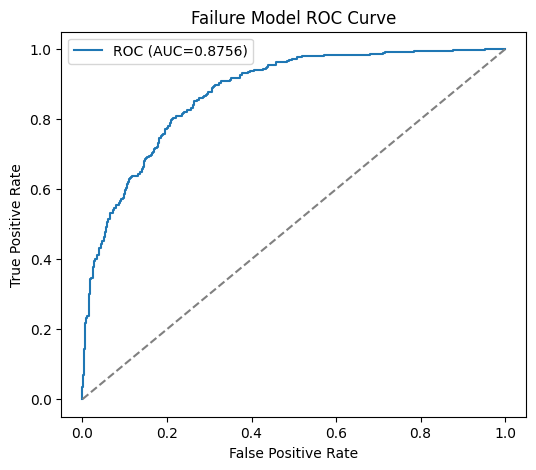

In [3]:
fpr, tpr = eval_data['roc_curve']
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"ROC (AUC={metrics['roc_auc']})")
plt.plot([0,1],[0,1],'--', color='gray')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('Failure Model ROC Curve'); plt.legend()
plt.show()

## SHAP explainability

In [4]:
from explainability import global_feature_importance, explain_prediction
importance = global_feature_importance(model)
importance

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[{'feature': 'Tool_Wear', 'importance_pct': 33.5},
 {'feature': 'Vibration', 'importance_pct': 13.2},
 {'feature': 'Torque', 'importance_pct': 11.9},
 {'feature': 'Temperature', 'importance_pct': 10.8},
 {'feature': 'Operating_Hours', 'importance_pct': 10.1},
 {'feature': 'Pressure', 'importance_pct': 5.9},
 {'feature': 'Rotational_Speed', 'importance_pct': 5.8},
 {'feature': 'Machine_Age_Years', 'importance_pct': 4.7},
 {'feature': 'Production_Load', 'importance_pct': 4.0},
 {'feature': 'Maintenance_Count', 'importance_pct': 0.2}]

In [5]:
sample_row = {
    'Temperature': 88, 'Vibration': 7.8, 'Pressure': 45, 'Rotational_Speed': 1300,
    'Torque': 58, 'Tool_Wear': 82, 'Operating_Hours': 1400, 'Machine_Age_Years': 6.2,
    'Maintenance_Count': 3, 'Production_Load': 0.9,
}
explain_prediction(model, scaler, sample_row)

[{'feature': 'Tool_Wear', 'contribution_pct': 35.4},
 {'feature': 'Temperature', 'contribution_pct': 27.5},
 {'feature': 'Vibration', 'contribution_pct': 25.5},
 {'feature': 'Torque', 'contribution_pct': 11.5}]

## Sample prediction

In [6]:
from failure_model import predict_failure
predict_failure(model, scaler, sample_row)

{'failure_probability': 0.9953,
 'prediction': 'Failure Risk Detected',
 'risk_level': 'HIGH'}